In [1]:
%pip install ucimlrepo
%pip install pandas
%pip install numpy
%pip install scikit-learn
%pip install matplotlib
%pip install ucimlrepo pandas numpy scikit-learn matplotlib 

In [12]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)

In [3]:
#### Experimento A - Predição de desistência e desempenho acadêmico de estudantes ###
#Seleção e compreensão da base de dados

# dataset predict_students_dropout_and_academic_success (estudantes)
estudantes = fetch_ucirepo(id=697) 
df_estudantes = pd.concat([estudantes.data.features, estudantes.data.targets], axis=1)

linhas_estudantes = df_estudantes.shape[0]
colunas_estudantes = df_estudantes.shape[1]

classes_estudantes = df_estudantes['Target'].unique()
contagem_classes_estudantes = df_estudantes['Target'].value_counts()
qntd_classes_estudantes = len(classes_estudantes)
porcentagem_classes_estudantes = (contagem_classes_estudantes / linhas_estudantes) * 100

distribuicao_estudantes = pd.DataFrame({
    'Quantidade': contagem_classes_estudantes,
    'Porcentagem (%)': porcentagem_classes_estudantes.round(2)
})

print("Número de linhas:", linhas_estudantes)
print("Número de colunas:", colunas_estudantes)
print("Distribuição das classes:")
print(distribuicao_estudantes)

Número de linhas: 4424
Número de colunas: 37
Distribuição das classes:
          Quantidade  Porcentagem (%)
Target                               
Graduate        2209            49.93
Dropout         1421            32.12
Enrolled         794            17.95


In [4]:
###Preparação dos dados###

#spoiler: nao tem valores nulos, nenhum dos dois datasets tem
valores_nulos_estudantes = df_estudantes.isnull().sum()
#print("Valores nulos por coluna:", valores_nulos_estudantes)

#O que queremos prever é 
x_estudantes = df_estudantes.drop('Target', axis=1)
y_estudantes = df_estudantes['Target']

# Identificar colunas
numericas = x_estudantes.select_dtypes(include=['number']).columns
categoricas = x_estudantes.select_dtypes(include=['object', 'category']).columns

# MinMaxScaler (entre 0 e 1) pra normalizar os atributos numéricos e OneHotEncoder (0 ou 1) pra codificar os atributos categóricos
preprocessador = ColumnTransformer(
    transformers=[
        ('numericas', MinMaxScaler(), numericas),
        ('categoricas', OneHotEncoder(handle_unknown='ignore'), categoricas)
    ]
)

# Dividir os dados mantendo a proporção das classes (20% para teste e 80% para treino)
X_treino, X_teste, y_treino, y_teste = train_test_split(
    x_estudantes, y_estudantes,
    test_size=0.2,
    random_state=42,
    stratify=y_estudantes
)

# Treinar as transformações
X_treino = preprocessador.fit_transform(X_treino)
X_teste = preprocessador.transform(X_teste)

print("Treinamento:", X_treino.shape)
print("Teste:", X_teste.shape)

print("Classes da variável-alvo:", y_estudantes.value_counts(), "\n")
print("\nQuantidade de atributos após processamento:", X_treino.shape[1], "\n")
print("\nQuantidade de registros de treinamento:", X_treino.shape[0], "\n")
print("\nQuantidade de registros de teste:", X_teste.shape[0], "\n")


Treinamento: (3539, 36)
Teste: (885, 36)
Classes da variável-alvo: Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64 


Quantidade de atributos após processamento: 36 


Quantidade de registros de treinamento: 3539 


Quantidade de registros de teste: 885 



In [5]:
#K-nearest neighbors
k = [5,10,20]

def K_nearest_neighbors(X_treino, y_treino, X_teste, y_teste):
    for element in k:
        knn = KNeighborsClassifier(n_neighbors=element)
        knn.fit(X_treino, y_treino)
        score = knn.score(X_teste, y_teste)
        print(f"Acurácia do KNN com {element} vizinhos: {score:.4f}")

In [6]:
#Naive Bayes
def Naive_Bayes(X_treino, y_treino, X_teste, y_teste):
    GaussianNB_model = GaussianNB()
    GaussianNB_model.fit(X_treino, y_treino)
    score = GaussianNB_model.score(X_teste, y_teste)
    print(f"Acurácia do Naive Bayes: {score:.4f}")

In [7]:
#Árvore de decisão
profundidade_maxima = [5, 10, 15]

def Decision_Tree(X_treino, y_treino, X_teste, y_teste):
    for element in profundidade_maxima:
        decision_tree = DecisionTreeClassifier(max_depth=element)
        decision_tree.fit(X_treino, y_treino)
        score = decision_tree.score(X_teste, y_teste)
        print(f"Acurácia da Árvore de Decisão com profundidade máxima {element}: {score:.4f}")

In [8]:
###Treinamento e comparação dos classificadores###
k_vizinho = K_nearest_neighbors(X_treino, y_treino, X_teste, y_teste)
bayes = Naive_Bayes(X_treino, y_treino, X_teste, y_teste)
arvore_decisao = Decision_Tree(X_treino, y_treino, X_teste, y_teste)

Acurácia do KNN com 5 vizinhos: 0.6452
Acurácia do KNN com 10 vizinhos: 0.6791
Acurácia do KNN com 20 vizinhos: 0.6859
Acurácia do Naive Bayes: 0.6588
Acurácia da Árvore de Decisão com profundidade máxima 5: 0.7548
Acurácia da Árvore de Decisão com profundidade máxima 10: 0.7186
Acurácia da Árvore de Decisão com profundidade máxima 15: 0.6960


Acurácia: 0.6452
Precisão: 0.6347
Recall: 0.6452
F1-score: 0.6391


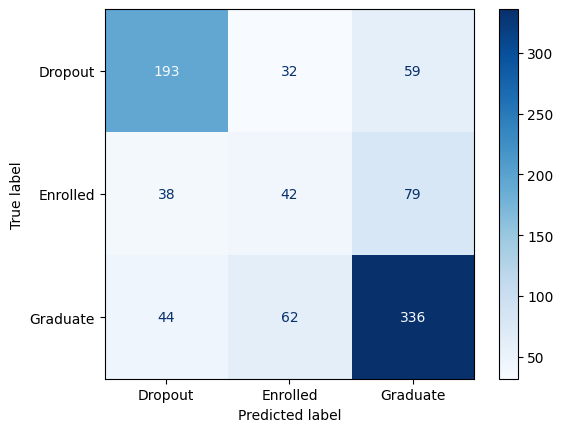

In [ ]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_treino, y_treino)
y_pred_classificacao = knn.predict(X_teste)

### Métricas ###
acuracia = accuracy_score(y_teste, y_pred_classificacao)
precisao = precision_score(y_teste, y_pred_classificacao, average='weighted')
recall = recall_score(y_teste, y_pred_classificacao, average='weighted')
f1 = f1_score(y_teste, y_pred_classificacao, average='weighted')

print(f"Acurácia: {acuracia:.4f}")  
print(f"Precisão: {precisao:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

matriz_confusao = confusion_matrix(y_teste, y_pred_classificacao)

### Exibição ###
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_confusao,
    display_labels=knn.classes_
)

disp.plot(cmap=plt.cm.Blues)
plt.show()